In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import random
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Input, Conv2D, Activation
from tensorflow.keras.models import Model
import h5py

In [ ]:
# load data
images = np.load('from_byclass36_images1000.npy')
labels = np.load('from_byclass36_labels1000.npy')

assert len(images) == len(labels)

# split dataset
train_images, test_images, train_labels, test_labels = train_test_split(
    images,
    labels,
    test_size=0.2,
    random_state=1,  
    shuffle=True    
)

In [ ]:
# print data
print(f"train_images shape: {train_images.shape}")
print(f"train_labels shape: {train_labels.shape}")
print(f"test_images shape: {test_images.shape}")
print(f"test_labels shape: {test_labels.shape}")

train_images shape: (28800, 28, 28)
train_labels shape: (28800,)
test_images shape: (7200, 28, 28)
test_labels shape: (7200,)


In [ ]:
import cv2

height, width = 20, 20

def preprocess_image(images, height, width):
    processed_images = []
    for img in images:
        # Resize
        resized = cv2.resize(img, (width, height), interpolation=cv2.INTER_AREA)

        # Normalize and binarize
        norm_img = resized / 255.0
        binary_img = (norm_img > 0.5).astype(np.uint8)

        # Transpose
        processed_images.append(binary_img.T)

    return np.array(processed_images)

train_images_trans = preprocess_image(train_images, height, width)
test_images_trans = preprocess_image(test_images, height, width)

In [ ]:
# 打印形状确认
print(f"train_images shape: {train_images_trans.shape}")
print(f"train_labels shape: {train_labels.shape}")
print(f"test_images shape: {test_images_trans.shape}")
print(f"test_labels shape: {test_labels.shape}")

train_images shape: (28800, 20, 20)
train_labels shape: (28800,)
test_images shape: (7200, 20, 20)
test_labels shape: (7200,)


In [ ]:
# Add channel dimension
if train_images_trans.ndim == 3:
    train_images_4dim = np.expand_dims(train_images_trans, -1)
    test_images_4dim = np.expand_dims(test_images_trans, -1)

# Check data shapes
print(f"train_images shape: {train_images_4dim.shape}")
print(f"train_labels shape: {train_labels.shape}")
print(f"test_images shape: {test_images_4dim.shape}")
print(f"test_labels shape: {test_labels.shape}")

train_images shape: (28800, 20, 20, 1)
train_labels shape: (28800,)
test_images shape: (7200, 20, 20, 1)
test_labels shape: (7200,)


In [ ]:
from tensorflow.keras import layers, models, backend as K
class GlobalSumPooling2D(layers.Layer):
    def call(self, inputs):
        return K.sum(inputs, axis=[1, 2])

In [ ]:
# build model
input_layer = Input(shape=(20, 20, 1))

x = Conv2D(filters=36, kernel_size=(10, 10), strides=(10, 10), use_bias=None)(input_layer)
x = Activation("relu")(x)
x = GlobalSumPooling2D()(x)  
output_layer = Activation("softmax")(x)

model = Model(inputs=input_layer, outputs=output_layer)

In [ ]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 20, 20, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 2, 2, 36)       │         3,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 2, 2, 36)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_sum_pooling2d            │ (None, 36)             │             0 │
│ (GlobalSumPooling2D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 36)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,600 (14.06 KB)

 Trainable params: 3,600 (14.06 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [ ]:
history = model.fit(
    train_images_4dim, train_labels,
    batch_size=64,
    epochs=1000,
    validation_data=(test_images_4dim, test_labels)
)

Epoch 1/1000
450/450 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.3191 - loss: 2.9651 - val_accuracy: 0.5822 - val_loss: 1.8309
Epoch 2/1000
450/450 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6113 - loss: 1.6742 - val_accuracy: 0.6458 - val_loss: 1.4071
Epoch 3/1000
450/450 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6600 - loss: 1.3360 - val_accuracy: 0.6771 - val_loss: 1.2322
Epoch 4/1000
450/450 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6846 - loss: 1.1929 - val_accuracy: 0.6956 - val_loss: 1.1265
Epoch 5/1000
450/450 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7051 - loss: 1.0870 - val_accuracy: 0.7147 - val_loss: 1.0471
Epoch 6/1000
450/450 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7202 - loss: 1.0050 - val_accuracy: 0.7269 - val_loss: 0.9886
Epoch 7/1000
450/450 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7357 - loss: 0.9599 - val_accuracy: 0.7332 - val_loss: 0.9518
Epoch 8/1000
450/450 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7421 - loss: 0.9163 - 

In [ ]:
loss, accuracy = model.evaluate(test_images_4dim, test_labels, verbose=0)  
print(f"Test Accuracy: {accuracy * 100:.2f}%")

Test Accuracy: 80.64%


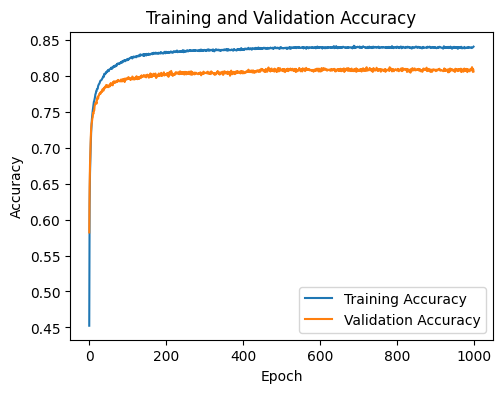

In [ ]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()

In [ ]:
model.save('byclass36-20x20-retrained-0711-2.h5')

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns

y_pred_probs = model.predict(test_images_4dim)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = test_labels.flatten()  

cm = confusion_matrix(y_true, y_pred)

225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [ ]:
plt.figure(figsize=(15, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=True)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
from tensorflow.keras.models import load_model
model = load_model("byclass36-20x20-retrained-0711-2.h5", custom_objects={'GlobalSumPooling2D': GlobalSumPooling2D})

In [ ]:
import pandas as pd

np.set_printoptions(precision=6, suppress=True, linewidth=np.inf)

conv_layer = model.layers[1]
filters = conv_layer.get_weights()[0]

print("Kernel weight shape:", filters.shape)

max_abs_weight = np.amax(np.abs(filters))
print("\nMaximum absolute weight:", max_abs_weight)

# Create an Excel file
output_excel_path = "conv_kernels_separate_sheets.xlsx"
writer = pd.ExcelWriter(output_excel_path, engine='openpyxl')

norm_weight = []

# Normalize and export each convolution kernel
for i in range(filters.shape[3]):
    kernel = filters[:, :, 0, i] / max_abs_weight
    print(f"\nNormalized weights of kernel {i+1}:")
    print(kernel)
    norm_weight.append(kernel)

    # Write each kernel to a separate sheet
    df = pd.DataFrame(kernel)
    sheet_name = f"Kernel_{i+1}"
    df.to_excel(writer, index=False, header=False, sheet_name=sheet_name)

# Save the Excel file
writer.close()
print(f"All kernel weights saved to {output_excel_path}.")

卷积核权重的形状: (10, 10, 1, 36)

所有卷积核中绝对值最大的权重值: 22.722471

卷积核 1 归一化权重:
[[-0.056467 -0.359477  0.032069 -0.01571  -0.012041  0.00605   0.020601  0.038947  0.010568 -0.015817]
 [-0.436825 -0.399133  0.012095 -0.001484 -0.000402  0.004906  0.021011  0.008035 -0.041971 -0.161973]
 [-0.003977 -0.014705 -0.011423  0.011732 -0.013301 -0.02707  -0.01745  -0.023971 -0.037136  0.002762]
 [ 0.031475  0.012714  0.020396  0.016022  0.00508  -0.004001 -0.009227 -0.026548  0.00447  -0.005432]
 [ 0.007649 -0.00131   0.037187  0.005037  0.01541   0.008042  0.005028 -0.02625  -0.015821  0.021306]
 [ 0.035514  0.022514  0.018633  0.016946  0.019727  0.02138   0.027368  0.01618   0.019945 -0.00475 ]
 [ 0.031704  0.003914  0.016562  0.011127  0.003422  0.0143    0.032138  0.028094  0.009695  0.012318]
 [ 0.051449 -0.01101  -0.008207 -0.015924  0.012476  0.001265  0.013468  0.021451  0.040181  0.011856]
 [ 0.014342 -0.067443 -0.025091  0.031918  0.013408 -0.000676 -0.014669 -0.017671 -0.022231 -0.033073]
 [-0.

In [ ]:
print(np.array(norm_weight).shape)
new_weights = np.moveaxis(norm_weight, 0, -1)[..., np.newaxis, :]
print("New shape:", new_weights.shape)

(36, 10, 10)
New shape: (10, 10, 1, 36)
